In [16]:
import pandas as pd
df = pd.read_csv("state_data.csv")


In [5]:
print(df.shape)

(52, 4)


In [6]:
#52 rows and 4 columns 

In [8]:
df.head()

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


In [9]:
df.tail()

,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


In [14]:
#the different columns are the first 5 and last 5 states soarted alphabeticlly. we are given lattituide, longitude, and name. 
#the first state is Alaska and the last is Wyoming.
#there are 51 enteries total.
#there are more than 50 states because purto rico was included. 

In [18]:
print(df["latitude"].median())
print(df["longitude"].median())

39.4355155
-89.093198


In [19]:
#these values are the median of the latitude and longitude

In [20]:
df["distance_to_lat"] = (df["latitude"] - df["latitude"].median()).abs()
df["distance_to_long"] = (df["longitude"] - df["longitude"].median()).abs()

In [22]:
print(df.shape)

(52, 6)


In [23]:
#52 columns and 6 rows.

In [30]:
lat_closest = df["distance_to_lat"].idxmin()
lat_futherst = df["distance_to_lat"].idxmax()
print(f"{df.loc[lat_closest, 'name']} {df.loc[lat_closest, 'distance_to_lat']:.2f}")
print(f"{df.loc[lat_futherst, 'name']} {df.loc[lat_futherst, 'distance_to_lat']:.2f}")

Colorado 0.11
Alaska 24.15


In [31]:
long_closest = df["distance_to_long"].idxmin()
long_futherst = df["distance_to_long"].idxmax()
print(f"{df.loc[long_closest, 'name']} {df.loc[long_closest, 'distance_to_long']:.2f}")
print(f"{df.loc[long_futherst,'name']} {df.loc[long_closest, 'distance_to_long']:.2f}")

Illinois 0.31
Hawaii 0.31


In [33]:
print(pd.get_dummies(df))

     latitude   longitude  distance_to_lat  distance_to_long  state_AK  \
0   63.588753 -154.493062        24.153237         65.399864      True   
1   32.318231  -86.902298         7.117285          2.190900     False   
2   35.201050  -91.831833         4.234465          2.738635     False   
3   34.048928 -111.093731         5.386588         22.000533     False   
4   36.778261 -119.417932         2.657255         30.324734     False   
5   39.550051 -105.782067         0.114536         16.688869     False   
6   41.603221  -73.087749         2.167705         16.005449     False   
7   38.905985  -77.033418         0.529530         12.059780     False   
8   38.910832  -75.527670         0.524684         13.565528     False   
9   27.664827  -81.515754        11.770689          7.577444     False   
10  32.157435  -82.907123         7.278081          6.186075     False   
11  19.898682 -155.665857        19.536834         66.572659     False   
12  41.878003  -93.097702         2.44

In [34]:
#I found get_dummies under the user guide on the pandas website. get_dummies (from my understanding, which isn't super strong) outputs true or false if a 0 is present in a row. 

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
df = sns.load_dataset("planets")


In [36]:
df = df.dropna(axis=1)

In [37]:
print(df.shape)

(1035, 3)


In [38]:
#the shape of my dataset is 3 columns with 1035 rows

In [39]:
print(df.head())

            method  number  year
0  Radial Velocity       1  2006
1  Radial Velocity       1  2008
2  Radial Velocity       1  2011
3  Radial Velocity       1  2007
4  Radial Velocity       1  2009


In [40]:
print(df.tail())

       method  number  year
1030  Transit       1  2006
1031  Transit       1  2007
1032  Transit       1  2007
1033  Transit       1  2008
1034  Transit       1  2008


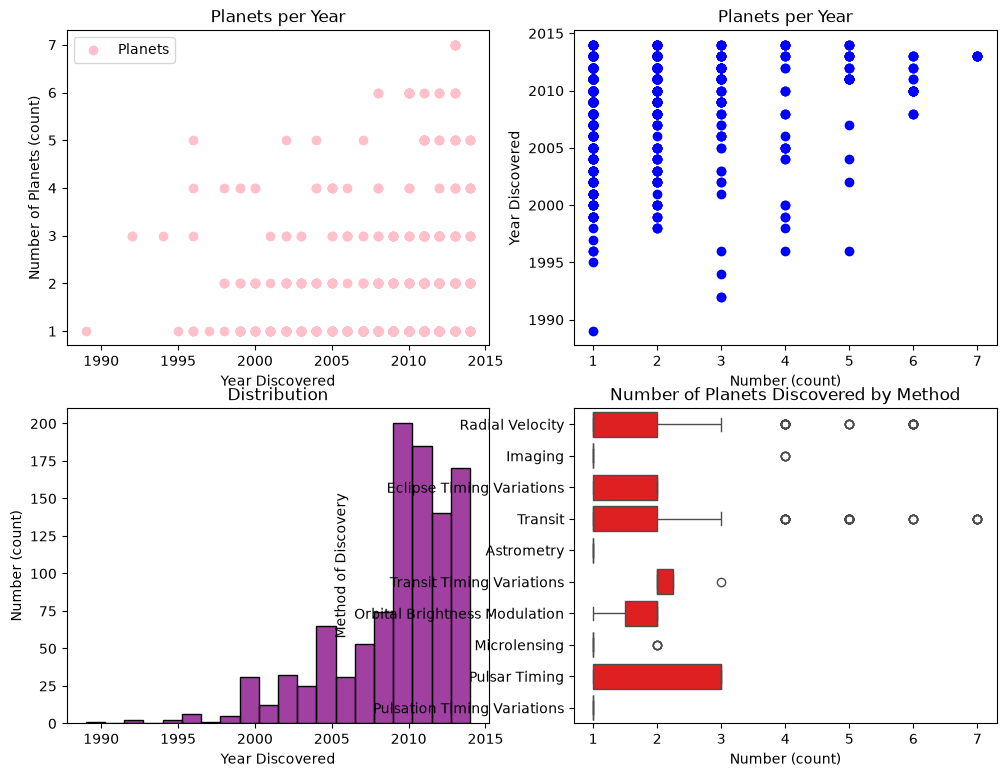

In [70]:
fig, axes = plt.subplots(2, 2, figsize = (12, 9))

axes[0,0].scatter(df["year"], df["number"], color = "pink", label="Planets")
axes[0,0].legend()
axes[0,0].set_xlabel("Year Discovered")
axes[0,0].set_ylabel("Number of Planets (count)")
axes[0,0].set_title("Planets per Year")

axes[0,1].scatter(df["number"], df["year"], color = "blue")
axes[0,1].set_xlabel("Number (count)")
axes[0,1].set_ylabel("Year Discovered")
axes[0,1].set_title("Planets per Year")

sns.histplot(data=df, x="year", bins=20, ax=axes[1,0], color = "purple")
axes[1,0].set_xlabel("Year Discovered")
axes[1,0].set_ylabel("Number (count)")
axes[1,0].set_title("Distribution")


sns.boxplot(data=df, x="number", y="method", ax=axes[1,1], color = "red")
axes[1,1].set_xlabel("Number (count)")
axes[1,1].set_ylabel("Method of Discovery")
axes[1,1].set_title("Number of Planets Discovered by Method")

plt.show()





In [71]:
#Each subplopt represents the number of planets that were discovered per year or the number of planets discovered by a method. I decided on these columns because I felt like I could learn the most of my data from these two columns. I learned that the most planets were discovered after 2005 and most planets were discovered by pulsar timing.